# Etapa 2 · Métricas de avaliação textual

Este notebook usa as tabelas salvas no fim do `etapa1.ipynb`. 

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666666", "grid.color": "#e6e6e6",
    "axes.labelcolor": "#191919", "xtick.color": "#666666", "ytick.color": "#666666",
})
CORES = {"train": "#257de0", "validation": "#f47230", "test": "#00b894"}
AZUL = CORES["train"]

DATA_DIR = Path("data")
PALAVRA = r"\w+(?:[-.,']\w+)*"          # mesmo padrão de palavra da Etapa 1

artigos = pd.read_parquet(DATA_DIR / "artigos.parquet")
artigos["split"] = pd.Categorical(artigos["split"], categories=list(CORES))

## 2.1Diversidade lexical

Diversidade lexical é o quanto um texto varia o vocabulário em vez de repetir as mesmas palavras. Todas as métricas desta seção trabalham só com a **forma** das palavras: `car` e `automobile` contam como palavras diferentes, e `bank` (banco) e `bank` (margem de rio) como a mesma. O significado fica para a seção de diversidade semântica.

### Tokens

Cada artigo vira uma lista de palavras em minúsculas, com o mesmo padrão `PALAVRA` da Etapa 1 (números também contam como palavra). Para entender as métricas, uso também uma frase de brinquedo em que dá para fazer as contas à mão.

In [2]:
artigos["tokens"] = artigos["text_limpo"].str.lower().str.findall(PALAVRA)
artigos["n_tokens"] = artigos["tokens"].str.len()

exemplo = "the cat saw the dog and the dog saw the cat".split()

print(f"{len(artigos)} artigos · {artigos['n_tokens'].sum():,} tokens · "
      f"menor artigo: {artigos['n_tokens'].min()} tokens · maior: {artigos['n_tokens'].max():,}")
print("exemplo:", exemplo)

720 artigos · 2,075,214 tokens · menor artigo: 226 tokens · maior: 16,088
exemplo: ['the', 'cat', 'saw', 'the', 'dog', 'and', 'the', 'dog', 'saw', 'the', 'cat']


### TTR (Type-Token Ratio)

**Definição:** a razão entre o número de palavras diferentes (*types*, V) e o total de palavras (*tokens*, N):

$$\text{TTR} = \frac{V}{N}$$

Vai de quase 0 (a mesma palavra repetida) até 1 (nenhuma palavra repetida). É a medida mais antiga e simples de diversidade lexical (Templin, 1957).

No exemplo, `the cat saw the dog and the dog saw the cat` tem 11 tokens e 5 types (`the`, `cat`, `saw`, `dog`, `and`), então TTR = 5/11 ≈ 0,45.

In [3]:
def ttr(tokens):
    return len(set(tokens)) / len(tokens)

print(f"exemplo: {ttr(exemplo):.3f}  (5/11)")

artigos["ttr"] = artigos["tokens"].map(ttr)

def spearman(a, b):
    return a.rank().corr(b.rank())                     # correlação de Spearman = Pearson dos postos

print(f"TTR por artigo: mediana {artigos['ttr'].median():.3f} · de {artigos['ttr'].min():.3f} a {artigos['ttr'].max():.3f}")
print(f"correlação (Spearman) entre TTR e tamanho do artigo: {spearman(artigos['ttr'], artigos['n_tokens']):.2f}")

exemplo: 0.455  (5/11)
TTR por artigo: mediana 0.353 · de 0.156 a 0.554
correlação (Spearman) entre TTR e tamanho do artigo: -0.82


**Interpretação:** a mediana é 0,35, ou seja, num artigo típico só ~1 em cada 3 palavras é nova. Mas a correlação com o tamanho é **−0,82**: quanto maior o artigo, menor o TTR. Isso acontece porque as palavras comuns (`the`, `of`, `and`) se repetem o texto todo, enquanto palavras novas aparecem cada vez mais devagar (é o mesmo efeito que fez o train ter TTR menor que validation e test na Etapa 1). Então, comparando artigos pelo TTR, o que se compara é principalmente o **tamanho**, não a diversidade.

**Limitações:**
- Depende do tamanho do texto, e por isso só compara textos de tamanho parecido. É a limitação mais conhecida e o motivo de MATTR e MTLD existirem.
- Olha só a forma das palavras: sinônimos contam como palavras diferentes e palavras iguais com sentidos diferentes contam como a mesma.
- Depende da tokenização: passar para minúsculas, contar números como palavras e juntar `well-known` numa palavra só mudam o valor.

### MATTR (Moving-Average TTR)

**Definição:** em vez de calcular o TTR no texto inteiro, calcula o TTR numa janela de tamanho fixo (W palavras) que desliza pelo texto, uma palavra por vez, e tira a média (Covington & McFall, 2010):

$$\text{MATTR} = \frac{1}{N - W + 1} \sum_{i=1}^{N-W+1} \text{TTR}(\text{tokens}_{i \ldots i+W-1})$$

Como toda janela tem o mesmo tamanho, o problema do TTR (cair quando o texto cresce) some. Usei **W = 100**, que cabe no menor artigo (226 tokens) e ainda deixa mais de 100 janelas por artigo.

No exemplo com W = 5, as janelas são `the cat saw the dog` (4 types → 0,8), `cat saw the dog and` (5 → 1,0), e assim por diante.
A implementação abaixo não recalcula cada janela do zero: guarda a contagem das palavras da janela e, a cada passo, tira a palavra que sai e põe a que entra. 

In [4]:
JANELA = 100

def mattr(tokens, janela=JANELA):
    cont = Counter(tokens[:janela])                    # palavras da primeira janela
    n_types = [len(cont)]
    for sai, entra in zip(tokens, tokens[janela:]):    # desliza uma palavra por vez
        cont[sai] -= 1
        if cont[sai] == 0:
            del cont[sai]
        cont[entra] += 1
        n_types.append(len(cont))
    return np.mean(n_types) / janela

print(f"exemplo (janela 5): {mattr(exemplo, 5):.3f}")

artigos["mattr"] = artigos["tokens"].map(mattr)

print(f"MATTR por artigo: mediana {artigos['mattr'].median():.3f} · de {artigos['mattr'].min():.3f} a {artigos['mattr'].max():.3f}")
print(f"correlação (Spearman) com o tamanho do artigo: {spearman(artigos['mattr'], artigos['n_tokens']):.2f}")

exemplo (janela 5): 0.800


MATTR por artigo: mediana 0.710 · de 0.588 a 0.777
correlação (Spearman) com o tamanho do artigo: 0.12


**Interpretação:** A mediana é 0,71: em qualquer trecho de 100 palavras de um artigo típico, ~71 são diferentes. E a correlação com o tamanho caiu de −0,82 (TTR) para **0,12**, então agora dá para comparar artigos grandes e pequenos.

**Limitações:**
- O valor depende da janela escolhida: MATTR com janela 100 e com janela 500 não são comparáveis entre si, e não existe uma janela "certa".
- Mede diversidade **local**: um artigo que repete as mesmas palavras em seções diferentes, mas varia dentro de cada trecho de 100 palavras, tem MATTR alto.
- Precisa de textos com pelo menos W palavras (aqui todos têm, o menor tem 226).

### MTLD (Measure of Textual Lexical Diversity)

**Definição:** mede **quantas palavras seguidas, em média, o texto consegue escrever antes de começar a se repetir demais**. O algoritmo:

1. Lê o texto palavra por palavra, calculando o TTR acumulado do trecho atual.
2. Quando o TTR cai até **0,72**, conta 1 **fator** e recomeça um trecho novo do zero.
3. No fim, o trecho que sobrou conta como fator parcial: $\frac{1 - \text{TTR}_{\text{resto}}}{1 - 0{,}72}$ (um resto que já caiu quase até 0,72 vale quase 1 fator).
4. MTLD = nº de tokens / nº de fatores.
5. Faz tudo de novo lendo o texto de trás para frente e tira a média dos dois sentidos.

Quanto **maior** o MTLD, mais palavras o texto consegue escrever antes de repetir, ou seja, mais diverso. O 0,72 é o valor que os autores testaram e recomendam. Como o resultado é um comprimento médio de trecho, ele não depende do tamanho total do texto.

Abaixo, o passo a passo nos primeiros tokens de um artigo: cada palavra aparece com o TTR acumulado, e `‖` marca onde o TTR chegou a 0,72 e um fator foi contado.

In [5]:
LIMIAR = 0.72

def mtld_sentido(tokens, limiar=LIMIAR):
    fatores, tipos, n = 0, set(), 0
    for t in tokens:
        n += 1
        tipos.add(t)
        if len(tipos) / n <= limiar:                   # o trecho ficou repetitivo: fecha um fator
            fatores += 1
            tipos, n = set(), 0
    if n > 0:                                          # fator parcial do trecho que sobrou
        fatores += (1 - len(tipos) / n) / (1 - limiar)
    return len(tokens) / fatores

def mtld(tokens, limiar=LIMIAR):
    return (mtld_sentido(tokens, limiar) + mtld_sentido(tokens[::-1], limiar)) / 2

def passo_a_passo(tokens, limiar=LIMIAR):
    saida, tipos, n = [], set(), 0
    for t in tokens:
        n += 1
        tipos.add(t)
        saida.append(f"{t}({len(tipos) / n:.2f})")
        if len(tipos) / n <= limiar:
            saida.append("‖")
            tipos, n = set(), 0
    print(" ".join(saida))

passo_a_passo(artigos.loc[0, "tokens"][:60])

senjō(1.00) no(1.00) valkyria(1.00) 3(1.00) unrecorded(1.00) chronicles(1.00) japanese(1.00) 戦場のヴァルキュリア3(1.00) lit(1.00) valkyria(0.90) of(0.91) the(0.92) battlefield(0.92) 3(0.86) commonly(0.87) referred(0.88) to(0.88) as(0.89) valkyria(0.84) chronicles(0.80) iii(0.81) outside(0.82) japan(0.83) is(0.83) a(0.84) tactical(0.85) role-playing(0.85) video(0.86) game(0.86) developed(0.87) by(0.87) sega(0.88) and(0.88) media.vision(0.88) for(0.89) the(0.86) playstation(0.86) portable(0.87) released(0.87) in(0.88) january(0.88) 2011(0.88) in(0.86) japan(0.84) it(0.84) is(0.83) the(0.81) third(0.81) game(0.80) in(0.78) the(0.76) valkyria(0.75) series(0.75) employing(0.76) the(0.75) same(0.75) fusion(0.75) of(0.74) tactical(0.73) and(0.72) ‖


In [6]:
artigos["mtld"] = artigos["tokens"].map(mtld)

print(f"MTLD por artigo: mediana {artigos['mtld'].median():.1f} · de {artigos['mtld'].min():.1f} a {artigos['mtld'].max():.1f}")
print(f"correlação (Spearman) com o tamanho do artigo: {spearman(artigos['mtld'], artigos['n_tokens']):.2f}")

MTLD por artigo: mediana 85.5 · de 38.4 a 147.6
correlação (Spearman) com o tamanho do artigo: 0.16


**Interpretação:** no passo a passo, o primeiro fator só fecha depois de 59 palavras: o começo de um artigo apresenta o assunto com muitas palavras novas, e o TTR vai caindo devagar até 0,72. A mediana é **85,5**: num artigo típico, o texto consegue em média ~85 palavras seguidas antes de ficar repetitivo. Vai de 38 (artigo mais repetitivo) a 148 (mais diverso), e a correlação com o tamanho é só **0,16**.

**Limitações:**
- O limiar 0,72 foi escolhido pelos autores testando textos em inglês. Outro limiar muda os valores (eles indicam a faixa de 0,66 a 0,75).
- Fica instável em textos curtos: os autores recomendam pelo menos 100 palavras, porque com poucos fatores o fator parcial do fim pesa muito.
- O fator parcial é uma aproximação (supõe que o TTR continuaria caindo no mesmo ritmo).
- Como as outras desta seção, só vê a forma das palavras.

### Distinct-N

**Definição:** a fração de n-gramas (sequências de n palavras seguidas) que são únicos (Li et al., 2016):

$$\text{Distinct-}n = \frac{\text{nº de n-gramas diferentes}}{\text{nº total de n-gramas}}$$

Distinct-1 é o próprio TTR. Distinct-2 e Distinct-3 olham pares e trios de palavras, então medem também a repetição de **expressões**, não só de palavras soltas. A métrica foi criada para avaliar texto gerado por modelos (respostas de chatbot muito repetitivas, como "I don't know", têm Distinct-N baixo).

No exemplo, os bigramas são `the cat`, `cat saw`, `saw the`, `the dog`, `dog and`, `and the`, `the dog`, `dog saw`, `saw the`, `the cat`: 10 no total e 7 diferentes, então Distinct-2 = 0,7.

Como o Distinct-N tem o mesmo problema de tamanho do TTR, calculei de dois jeitos:
- **por split**, com o split inteiro e com todos cortados no tamanho do menor (validation, ~178 mil tokens);
- **por artigo**, como a média em blocos de 200 tokens seguidos.

In [7]:
def ngramas(tokens, n):
    return list(zip(*(tokens[i:] for i in range(n))))

def distinct(tokens, n):
    g = ngramas(tokens, n)
    return len(set(g)) / len(g)

print(f"exemplo: Distinct-1 = {distinct(exemplo, 1):.3f} · Distinct-2 = {distinct(exemplo, 2):.3f}")

por_split = artigos.groupby("split", observed=True)["tokens"].sum()     # junta os artigos de cada split
menor = por_split.str.len().min()
linhas = {}
for split, tokens in por_split.items():
    for nome, t in [("inteiro", tokens), (f"primeiros {menor:,}", tokens[:menor])]:
        linhas[(split, nome)] = {"tokens": len(t), **{f"distinct_{n}": distinct(t, n) for n in (1, 2, 3)}}
pd.DataFrame(linhas).T.round(3)

exemplo: Distinct-1 = 0.455 · Distinct-2 = 0.700


tokens  distinct_1  distinct_2  distinct_3
train      inteiro            1697200.0       0.046       0.420       0.791
           primeiros 177,909   177909.0       0.113       0.594       0.889
validation inteiro             177909.0       0.108       0.583       0.877
           primeiros 177,909   177909.0       0.108       0.583       0.877
test       inteiro             200105.0       0.103       0.572       0.872
           primeiros 177,909   177909.0       0.107       0.579       0.875

In [8]:
BLOCO = 200

def distinct_blocos(tokens, n, bloco=BLOCO):
    blocos = [tokens[i:i + bloco] for i in range(0, len(tokens) - bloco + 1, bloco)]
    return np.mean([distinct(b, n) for b in blocos])

for n in (1, 2, 3):
    artigos[f"distinct_{n}"] = artigos["tokens"].map(lambda t: distinct_blocos(t, n))
artigos["distinct_2_inteiro"] = artigos["tokens"].map(lambda t: distinct(t, 2))

print(artigos[["distinct_1", "distinct_2", "distinct_3"]].describe().loc[["mean", "50%", "min", "max"]].round(3))
print(f"\ncorrelação (Spearman) com o tamanho: Distinct-2 no artigo inteiro = {spearman(artigos['distinct_2_inteiro'], artigos['n_tokens']):.2f} · "
      f"em blocos de {BLOCO} = {spearman(artigos['distinct_2'], artigos['n_tokens']):.2f}")

      distinct_1  distinct_2  distinct_3
mean       0.615       0.929       0.983
50%        0.619       0.934       0.987
min        0.445       0.781       0.894
max        0.692       0.976       0.999

correlação (Spearman) com o tamanho: Distinct-2 no artigo inteiro = -0.52 · em blocos de 200 = 0.28


**Interpretação:**
- **Por split:** com o split inteiro, o train parece muito menos diverso (Distinct-1 = 0,046 contra 0,108 do validation). Cortando todos no mesmo tamanho (177.909 tokens), o train vai para 0,113 e fica praticamente igual aos outros (0,108 e 0,107). Ou seja, a diferença era **só tamanho**, como já tinha aparecido no TTR da Etapa 1. O mesmo vale para Distinct-2 e Distinct-3.
- **Por artigo (blocos de 200):** a média é 0,62 para Distinct-1, 0,93 para Distinct-2 e 0,98 para Distinct-3. Em texto de enciclopédia quase nenhum par ou trio de palavras se repete dentro de 200 palavras, então Distinct-3 fica perto do teto e quase não diferencia os artigos.
- Calculando no artigo inteiro, o Distinct-2 tem correlação de −0,52 com o tamanho; nos blocos de 200 isso some (0,28, e com sinal positivo).

**Limitações:**
- Tem o mesmo problema de tamanho do TTR, então precisa de blocos ou cortes de tamanho fixo para comparar.
- Foi criado para texto **gerado** por modelos, onde repetição é um defeito comum. Em texto humano, n ≥ 3 satura perto de 1 e perde poder de diferenciar.
- No nível do split, os n-gramas atravessam a fronteira entre um artigo e o seguinte. Isso cria alguns n-gramas falsos, mas são poucos perto de milhões de tokens.

### Comparando as métricas lexicais

Com as quatro métricas calculadas para os 720 artigos, falta ver duas coisas: quais dependem do tamanho do texto e se elas concordam entre si.

**Gráfico 2.1** · As métricas dependem do tamanho do artigo?

A principal crítica ao TTR é depender do tamanho do texto, e MATTR, MTLD e o Distinct-N em blocos foram usados justamente para resolver isso. Este gráfico verifica se resolveram.

- cada ponto é um artigo, com o tamanho no eixo x (escala log) e o valor da métrica no eixo y, colorido pelo split. No título está a correlação de Spearman com o tamanho: perto de 0, a métrica não depende do tamanho; perto de −1 ou 1, depende muito.

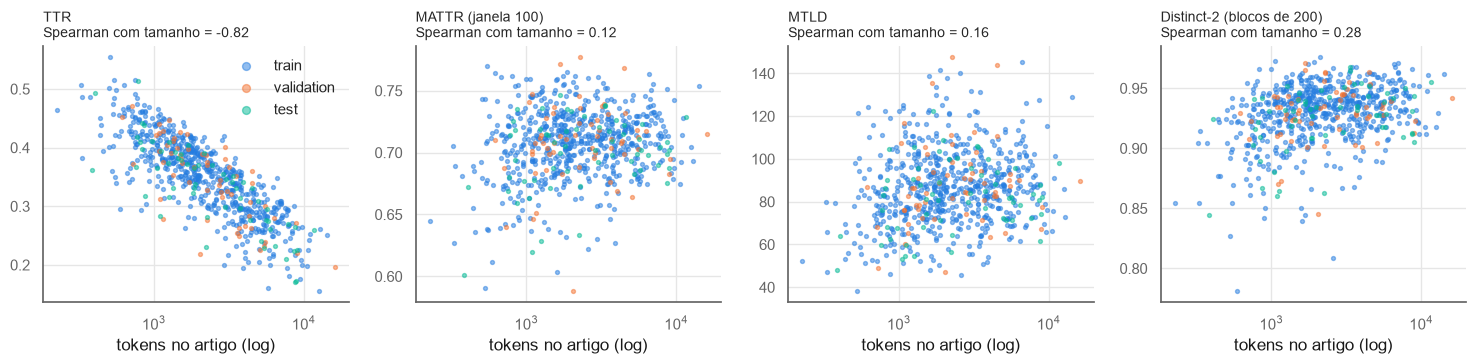

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True)
for ax, (col, nome) in zip(axes, [("ttr", "TTR"), ("mattr", f"MATTR (janela {JANELA})"),
                                  ("mtld", "MTLD"), ("distinct_2", f"Distinct-2 (blocos de {BLOCO})")]):
    for split, cor in CORES.items():
        parte = artigos[artigos["split"] == split]
        ax.scatter(parte["n_tokens"], parte[col], s=8, alpha=0.5, color=cor, label=split)
    ax.set_xscale("log")
    ax.set(xlabel="tokens no artigo (log)")
    ax.set_title(f"{nome}\nSpearman com tamanho = {spearman(artigos[col], artigos['n_tokens']):.2f}", loc="left", fontsize=10)
axes[0].legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

- O TTR desce em diagonal (−0,82): só de olhar o tamanho do artigo já dá para adivinhar o TTR dele.
- MATTR (0,12), MTLD (0,16) e Distinct-2 em blocos (0,28) formam nuvens quase horizontais, então a dependência do tamanho praticamente sumiu.
- O pouco de correlação positiva que sobra pode ser real e não um defeito: vários dos artigos curtos são de tipos repetitivos (estradas, listas de prêmios, ver a tabela de extremos), enquanto os longos costumam ser texto narrativo mais elaborado.
- Os três splits se misturam nas nuvens: nenhum é mais ou menos diverso que os outros.

**Gráfico 2.2** · As métricas concordam entre si?

Se duas métricas medem a mesma coisa, elas devem ordenar os artigos do mesmo jeito. Se discordam, ou medem coisas diferentes ou uma delas está sendo distorcida por outro fator (como o tamanho). Isso também responde à pergunta da Etapa 4 sobre métricas que levam a conclusões contraditórias.

- cada célula é a correlação de Spearman entre duas métricas nos 720 artigos. Vermelho escuro (perto de 1) quer dizer que as duas ordenam os artigos quase do mesmo jeito, branco (perto de 0) que não têm relação e azul que andam em sentidos opostos.

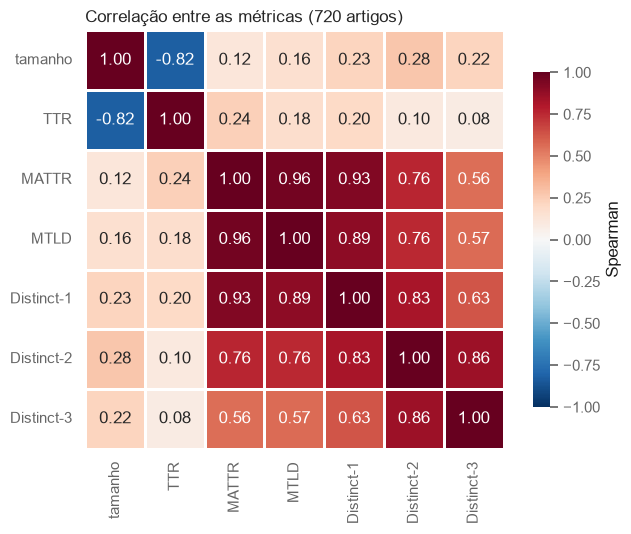

In [10]:
metricas = {"n_tokens": "tamanho", "ttr": "TTR", "mattr": "MATTR", "mtld": "MTLD",
            "distinct_1": "Distinct-1", "distinct_2": "Distinct-2", "distinct_3": "Distinct-3"}
corr = artigos[list(metricas)].rank().corr().rename(index=metricas, columns=metricas)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor="white", cbar_kws={"label": "Spearman", "shrink": 0.8}, ax=ax)
ax.set_title("Correlação entre as métricas (720 artigos)", loc="left")
plt.tight_layout()
plt.show()

- **MATTR e MTLD medem quase a mesma coisa (0,96).** Os dois controlam o tamanho de jeitos diferentes, janela fixa e comprimento médio de trecho, e chegam na mesma ordenação. Para as próximas etapas basta usar uma delas como principal: escolhi o **MTLD**, que não depende de escolher uma janela.
- **O TTR discorda de todas as outras (0,08 a 0,24)** e só se correlaciona com o tamanho (−0,82). Então um ranking de "artigos mais diversos" feito pelo TTR daria uma conclusão diferente da feita pelo MTLD. Esse é um exemplo concreto de métricas que levam a conclusões contraditórias.
- **Quanto maior o n, mais o Distinct-N se afasta do MTLD** (0,89 → 0,76 → 0,57). O Distinct-1 em blocos é quase um MATTR com outra janela. Já o Distinct-3 mede outra coisa (repetição de expressões), mas, como está perto do teto, essa informação é pequena.

**Extremos e splits** · quais artigos são mais e menos diversos?

Para dar cara aos números, os 5 artigos com menor e maior MTLD, e a mediana das métricas em cada split.

In [11]:
cols = ["split", "artigo", "n_tokens", "ttr", "mattr", "mtld", "distinct_2"]
display(artigos.nsmallest(5, "mtld")[cols].round(3),
        artigos.nlargest(5, "mtld")[cols].round(3),
        artigos.groupby("split", observed=True)[["n_tokens", "ttr", "mattr", "mtld", "distinct_1", "distinct_2", "distinct_3"]].median().round(3))

,split,artigo,n_tokens,ttr,mattr,mtld,distinct_2
194,train,Hope Highway,527,0.361,0.590,38.366,0.827
90,train,"Papal conclave, 1769",2599,0.312,0.622,45.691,0.809
44,train,Grammy Award for Best Concept Music Video,878,0.377,0.648,46.339,0.863
114,train,New York State Route 368,329,0.383,0.627,47.204,0.854
620,validation,New Jersey Route 29,2044,0.219,0.588,47.333,0.845


,split,artigo,n_tokens,ttr,mattr,mtld,distinct_2
653,validation,Back Off Boogaloo,2276,0.370,0.777,147.598,0.964
588,train,Wilhelm Busch,6614,0.349,0.764,145.131,0.970
624,validation,Air Rhodesia Flight 825,4504,0.339,0.768,144.122,0.963
509,train,Diamond stingray,1876,0.416,0.765,141.660,0.959
83,train,Of Human Feelings,2569,0.372,0.760,140.031,0.967


,n_tokens,ttr,mattr,mtld,distinct_1,distinct_2,distinct_3
split,,,,,,,
train,1992.0,0.355,0.711,85.784,0.620,0.934,0.987
validation,2253.0,0.357,0.710,86.386,0.620,0.931,0.986
test,2199.0,0.335,0.702,82.051,0.612,0.931,0.985


In [12]:
for titulo in artigos.nsmallest(3, "mtld")["artigo"]:
    texto = artigos.loc[artigos["artigo"] == titulo, "text_limpo"].iloc[0]
    print(f"--- {titulo}\n{texto[:400]}...\n")

--- Hope Highway
The Hope Highway, also known as the Hope Road Turnoff, is a Forest Highway located in the Kenai Peninsula Borough, in the U.S. state of Alaska. The highway connects the city of Hope to the Seward Highway, and travels through 17 miles (27 km) of the Chugach National Forest. The road passes the ghost town of Sunrise City and several smaller settlements, remnants of the gold rush that occurred in tha...

--- Papal conclave, 1769
A papal conclave which lasted from 15 February to 19 May 1769 was convoked after the death of Pope Clement XIII. It elected as his successor Cardinal Lorenzo Ganganelli, who took the name Clement XIV.
Clement XIII died suddenly on 2 February 1769, a day before the date of the consistory that he had convoked to examine the demands for the general suppression of the Society of Jesus. The various cou...

--- Grammy Award for Best Concept Music Video
The Grammy Award for Best Concept Music Video was an award that was presented to recording artists at 

**O que os extremos mostram:**
- **Menor MTLD:** `Hope Highway`, `New York State Route 368` e `New Jersey Route 29` são artigos de estradas, que descrevem o trajeto repetindo o mesmo vocabulário (`route`, `road`, `highway`, o número da estrada e os nomes de cidades). `Papal conclave, 1769` repete títulos e nomes de cardeais (`cardinal-priest` é a palavra de conteúdo mais frequente) e `Grammy Award for Best Concept Music Video` gira em torno de `video`, `music` e `award`. A baixa diversidade vem do **tipo de artigo**, não de texto mal escrito.
- **Maior MTLD:** uma música (`Back Off Boogaloo`), um artista (`Wilhelm Busch`), um acidente aéreo, um animal (`Diamond stingray`) e um álbum. São textos narrativos ou descritivos, que vão apresentando coisas diferentes ao longo do artigo.
- **Por split:** as medianas são praticamente iguais (MTLD de 85,8 / 86,4 / 82,1, MATTR de 0,71 / 0,71 / 0,70). Os splits não diferem em diversidade lexical, só em assunto (Gráfico 5 da Etapa 1).
- Isso sugere que a diversidade lexical **varia com o assunto**. Vou voltar a isso depois de encontrar os tópicos (pergunta 6 da Etapa 3).

### Resumo da diversidade lexical

- O WikiText-2 tem diversidade lexical alta e homogênea: MTLD mediano de 85 palavras, MATTR de 0,71, e quase nenhum bigrama ou trigrama repetido dentro de 200 palavras.
- **O TTR não serve para comparar artigos** neste dataset: ele mede principalmente o tamanho (−0,82) e discorda das outras métricas.
- **MATTR e MTLD concordam (0,96) e não dependem do tamanho.** Uso o MTLD como métrica lexical principal daqui em diante.
- Os splits têm a mesma diversidade lexical. As diferenças que aparecem em contagens brutas (Distinct-N e TTR por split) são efeito do tamanho.
- Os artigos menos diversos são de tipos com texto em fórmula (estradas, listas de prêmios ou de pessoas), o que liga diversidade lexical ao assunto.
- Todas essas métricas olham só a **forma** das palavras. Se dois artigos falam da mesma coisa com palavras diferentes, ou de coisas diferentes com as mesmas palavras, elas não percebem. Isso é o que a próxima seção (diversidade semântica) vai medir.

### Referências

- Templin, M. C. (1957). *Certain language skills in children: Their development and interrelationships*. University of Minnesota Press. (origem do TTR)
- Covington, M. A., & McFall, J. D. (2010). Cutting the Gordian knot: The moving-average type–token ratio (MATTR). *Journal of Quantitative Linguistics*, 17(2), 94–100.
- McCarthy, P. M., & Jarvis, S. (2010). MTLD, vocd-D, and HD-D: A validation study of sophisticated approaches to lexical diversity assessment. *Behavior Research Methods*, 42(2), 381–392.
- Li, J., Galley, M., Brockett, C., Gao, J., & Dolan, B. (2016). A diversity-promoting objective function for neural conversation models. *Proceedings of NAACL-HLT 2016*, 110–119.